# Entrenamiento

In [1]:
from pathlib import Path
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import numpy as np
import copy
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from utilidades.preparar_dataset import preparar_kdef
from utilidades.extraer_caracteristicas import extraer_dataset, crear_landmarker, extraer_de_imagen, leer_imagen
from utilidades.modelo_emociones import ClasificadorEmociones

In [2]:
RUTA_KDEF = Path(r"C:\Users\alici\Downloads\KDEF_and_AKDEF\KDEF_and_AKDEF\KDEF")   # cambia en cada ordenador

CARPETA_DATOS         = Path("datos")
CARPETA_ENTRENAMIENTO = Path("entrenamiento")
CARPETA_DATOS.mkdir(exist_ok=True)
CARPETA_ENTRENAMIENTO.mkdir(exist_ok=True)

RUTA_INDICE          = CARPETA_DATOS / "kdef_index.csv"
RUTA_CARACTERISTICAS = CARPETA_DATOS / "kdef_caracteristicas.npz"
RUTA_MODELO          = Path("modelos_externos") / "face_landmarker.task"
ENTRENAR = False

df = preparar_kdef(RUTA_KDEF, salida=RUTA_INDICE)

df_usar = df[df["usar"]].reset_index(drop=True)
df_usar.head()

datos = extraer_dataset(df_usar, ruta_modelo=RUTA_MODELO, salida=RUTA_CARACTERISTICAS)

La limpieza ya estaba hecha. Cargando C:\Users\alici\Downloads\VC\P5\datos\kdef_index.csv
Imágenes que se usan: 2938 de 4900
La extracción ya estaba hecha. Cargando C:\Users\alici\Downloads\VC\P5\datos\kdef_caracteristicas.npz
Caras: 2934 · landmarks por cara: 478 · blendshapes: 52


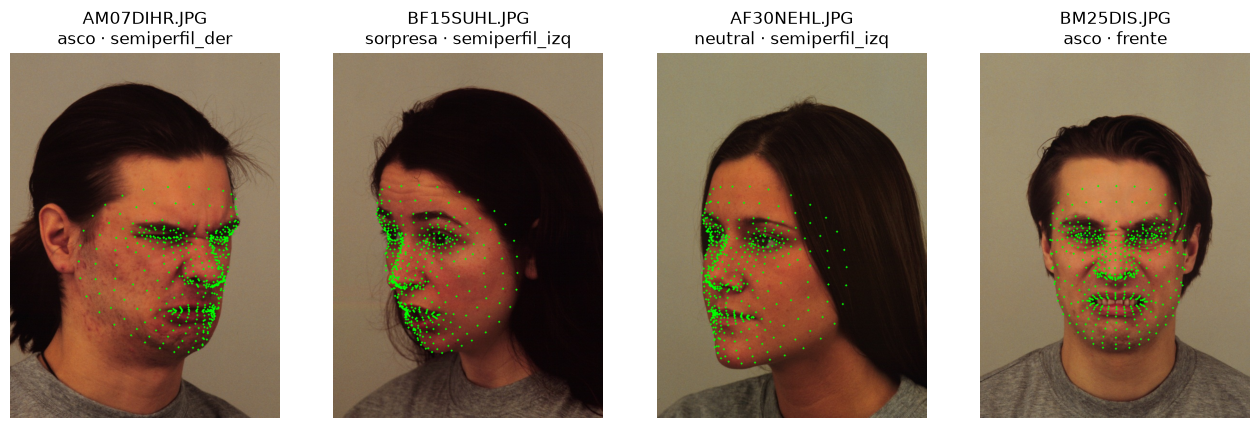

In [3]:
muestras = df_usar.sample(4, random_state=0)
fig, ejes = plt.subplots(1, 4, figsize=(16, 5))

with crear_landmarker(RUTA_MODELO, modo="imagen") as lmk:
    for eje, fila in zip(ejes, muestras.itertuples()):
        img = leer_imagen(fila.ruta)
        rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        import mediapipe as mp
        res = lmk.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
        if res.face_landmarks:
            h, w = img.shape[:2]
            for p in res.face_landmarks[0]:
                cv2.circle(rgb, (int(p.x * w), int(p.y * h)), 2, (0, 255, 0), -1)
        eje.imshow(rgb)
        eje.set_title(f"{fila.archivo}\n{fila.emocion} · {fila.angulo}")
        eje.axis("off")
plt.show()

In [4]:
# ---------- Características: absolutas, delta (menos la neutra) o ambas ----------
def indices_neutra_referencia(datos):
    """Para cada cara, índice de la foto NEUTRA de la misma persona y ángulo,
    preferiblemente de la OTRA sesión (dos neutras nunca son idénticas, como en la
    calibración del juego). Si no existe, usa la de la misma sesión. -1 si no hay ninguna."""
    neutras = {}
    for i, (p, s, a, e) in enumerate(zip(datos["persona"], datos["sesion"], datos["angulo"], datos["y"])):
        if e == "neutral":
            neutras[(p, s, a)] = i
    ref = np.full(len(datos["y"]), -1)
    for i, (p, s, a) in enumerate(zip(datos["persona"], datos["sesion"], datos["angulo"])):
        otra = "B" if s == "A" else "A"
        ref[i] = neutras.get((p, otra, a), neutras.get((p, s, a), -1))
    return ref

def construir_X(datos, tipo):
    """Devuelve (X, valido). 'valido' marca las caras que tienen neutra de referencia."""
    lm = datos["X_lm"]
    n = len(lm)
    absoluto = lm.reshape(n, -1)
    if tipo == "absoluto":
        return absoluto, np.ones(n, dtype=bool)
    ref = indices_neutra_referencia(datos)
    valido = (ref >= 0) & (ref != np.arange(n))   # una neutra no puede restarse a sí misma
    delta = np.zeros_like(absoluto)
    delta[valido] = (lm[valido] - lm[ref[valido]]).reshape(valido.sum(), -1)
    if tipo == "delta":
        return delta, valido
    if tipo == "ambos":
        return np.hstack([absoluto, delta]), valido
    raise ValueError(f"Tipo desconocido: {tipo}")

In [5]:
# ---------- División por personas ----------
SEMILLA = 42   # para que la división sea siempre la misma

TIPO_CARACT = "ambos"   # "absoluto", "delta" o "ambos" (lo decidiremos con el kfold)
CARPETA_TIPO = CARPETA_ENTRENAMIENTO / TIPO_CARACT     # entrenamiento/absoluto, entrenamiento/ambos...
CARPETA_TIPO.mkdir(parents=True, exist_ok=True)
RUTA_RED = CARPETA_TIPO / "modelo.pt"

X, valido = construir_X(datos, TIPO_CARACT)
X        = X[valido]
y_texto  = datos["y"][valido]
personas = datos["persona"][valido]
angulos  = datos["angulo"][valido]
print(f"Caras sin neutra de referencia (descartadas): {(~valido).sum()}")

# Emociones en orden fijo -> números 0..6 (este orden lo necesitará el filtro)
EMOCIONES = sorted(np.unique(y_texto).tolist())
y = np.array([EMOCIONES.index(e) for e in y_texto])

# Mezclamos a las personas de cada sexo por separado y repartimos 25/5/5
rng = np.random.default_rng(SEMILLA)
mujeres = rng.permutation(sorted({p for p in personas if p.startswith("F")}))
hombres = rng.permutation(sorted({p for p in personas if p.startswith("M")}))

def repartir(lista, n_val=5, n_test=5):
    return lista[n_val + n_test:], lista[:n_val], lista[n_val:n_val + n_test]

f_tr, f_va, f_te = repartir(mujeres)
m_tr, m_va, m_te = repartir(hombres)
pers_train = set(f_tr) | set(m_tr)
pers_val   = set(f_va) | set(m_va)
pers_test  = set(f_te) | set(m_te)

# Comprobación: ninguna persona puede estar en dos grupos
assert not (pers_train & pers_val) and not (pers_train & pers_test) and not (pers_val & pers_test)

idx_train = np.isin(personas, list(pers_train))
idx_val   = np.isin(personas, list(pers_val))
idx_test  = np.isin(personas, list(pers_test))

X_train, y_train = X[idx_train], y[idx_train]
X_val,   y_val   = X[idx_val],   y[idx_val]
X_test,  y_test  = X[idx_test],  y[idx_test]

# Estandarizar: media 0 y desviación 1 por característica.
# Se calcula SOLO con entrenamiento y se aplica igual a validación y test (y luego al filtro).
escalador = StandardScaler().fit(X_train)
X_train = escalador.transform(X_train).astype(np.float32)
X_val   = escalador.transform(X_val).astype(np.float32)
X_test  = escalador.transform(X_test).astype(np.float32)

# ---------- Resumen ----------
print(f"Características por cara: {X.shape[1]}  (tipo: {TIPO_CARACT})\n")
for nombre, pers, yy in [("Entrenamiento", pers_train, y_train),
                         ("Validación", pers_val, y_val),
                         ("Test", pers_test, y_test)]:
    n_f = sum(p.startswith("F") for p in pers)
    print(f"{nombre:14s} {len(pers):2d} personas ({n_f} mujeres, {len(pers) - n_f} hombres) · {len(yy)} caras")

print("\nCaras por emoción en cada conjunto:")
print(pd.DataFrame({"train": np.bincount(y_train, minlength=7),
                    "val":   np.bincount(y_val,   minlength=7),
                    "test":  np.bincount(y_test,  minlength=7)},
                   index=EMOCIONES).to_string())
print("\nPersonas de test:", sorted(str(p) for p in pers_test))

Caras sin neutra de referencia (descartadas): 2
Características por cara: 2868  (tipo: ambos)

Entrenamiento  50 personas (25 mujeres, 25 hombres) · 2097 caras
Validación     10 personas (5 mujeres, 5 hombres) · 418 caras
Test           10 personas (5 mujeres, 5 hombres) · 417 caras

Caras por emoción en cada conjunto:
          train  val  test
alegria     300   60    60
asco        299   60    59
enfado      300   60    60
miedo       300   60    60
neutral     298   60    58
sorpresa    300   59    60
tristeza    300   59    60

Personas de test: ['F08', 'F11', 'F21', 'F30', 'F35', 'M08', 'M18', 'M22', 'M33', 'M35']


In [6]:
torch.manual_seed(SEMILLA)
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
print("Entrenando en:", dispositivo)

modelo = ClasificadorEmociones(X_train.shape[1], n_clases=len(EMOCIONES)).to(dispositivo)
print(modelo)
print("Parámetros entrenables:", sum(p.numel() for p in modelo.parameters() if p.requires_grad))

Entrenando en: cuda
ClasificadorEmociones(
  (red): Sequential(
    (0): Linear(in_features=2868, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.4, inplace=False)
    (8): Linear(in_features=256, out_features=128, bias=True)
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.4, inplace=False)
    (12): Linear(in_features=128, out_features=7, bias=True)
  )
)
Parámetros entrenables: 1635847


In [7]:
TAM_LOTE   = 64
LR         = 1e-3
EPOCAS_MAX = 300
PACIENCIA  = 25     # early-stopping: épocas sin mejorar antes de parar
RUIDO      = 0.1    # intensidad del ruido de data augmentation

def crear_loader(X, y, barajar, descartar_ultimo=False):
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y).long())
    return DataLoader(ds, batch_size=TAM_LOTE, shuffle=barajar, drop_last=descartar_ultimo)

loader_train      = crear_loader(X_train, y_train, barajar=True, descartar_ultimo=True)
loader_train_eval = crear_loader(X_train, y_train, barajar=False)
loader_val        = crear_loader(X_val, y_val, barajar=False)

criterio = nn.CrossEntropyLoss()

def evaluar(modelo, loader):
    modelo.eval()
    perdida, aciertos, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(dispositivo), yb.to(dispositivo)
            salida = modelo(xb)
            perdida  += criterio(salida, yb).item() * len(yb)
            aciertos += (salida.argmax(1) == yb).sum().item()
            total    += len(yb)
    return perdida / total, aciertos / total


if ENTRENAR:
    if RUTA_RED.exists():
        print(f"Aviso: se sobrescribirá {RUTA_RED}\n")

    optimizador = torch.optim.AdamW(modelo.parameters(), lr=LR, weight_decay=1e-3)
    historial = {"loss_train": [], "loss_val": [], "acc_train": [], "acc_val": []}
    mejor_loss, mejor_estado, mejor_epoca, sin_mejora = float("inf"), None, 0, 0

    for epoca in range(1, EPOCAS_MAX + 1):
        # --- entrenamiento ---
        modelo.train()
        for xb, yb in loader_train:
            xb, yb = xb.to(dispositivo), yb.to(dispositivo)
            xb = xb + RUIDO * torch.randn_like(xb)          # data augmentation
            optimizador.zero_grad()
            perdida = criterio(modelo(xb), yb)
            perdida.backward()
            optimizador.step()

        # --- evaluación ---
        loss_tr, acc_tr = evaluar(modelo, loader_train_eval)
        loss_va, acc_va = evaluar(modelo, loader_val)
        historial["loss_train"].append(loss_tr); historial["acc_train"].append(acc_tr)
        historial["loss_val"].append(loss_va);   historial["acc_val"].append(acc_va)

        # --- early stopping ---
        if loss_va < mejor_loss - 1e-4:
            mejor_loss, mejor_epoca, sin_mejora = loss_va, epoca, 0
            mejor_estado = copy.deepcopy(modelo.state_dict())
        else:
            sin_mejora += 1

        if epoca == 1 or epoca % 10 == 0:
            print(f"Época {epoca:3d} · loss train {loss_tr:.3f} · loss val {loss_va:.3f} · "
                  f"acc train {acc_tr:.3f} · acc val {acc_va:.3f}")

        if sin_mejora >= PACIENCIA:
            print(f"\nEarly stopping en la época {epoca}.")
            break

    modelo.load_state_dict(mejor_estado)

    # --- guardar todo lo necesario para el filtro ---
    torch.save({
        "estado_modelo": modelo.state_dict(),
        "tipo_caracteristicas": TIPO_CARACT,
        "arquitectura": {"n_entrada": X_train.shape[1], "n_clases": len(EMOCIONES),
                         "ocultas": (512, 256, 128), "dropout": 0.4},
        "emociones": EMOCIONES,
        "escalador_media": torch.tensor(escalador.mean_, dtype=torch.float32),
        "escalador_escala": torch.tensor(escalador.scale_, dtype=torch.float32),
        "historial": historial,
        "mejor_epoca": mejor_epoca,
        "hiperparametros": {"tam_lote": TAM_LOTE, "lr": LR, "paciencia": PACIENCIA,
                            "ruido": RUIDO, "semilla": SEMILLA},
    }, RUTA_RED)
    print(f"\nModelo guardado en {RUTA_RED.resolve()}")

else:
    if not RUTA_RED.exists():
        raise FileNotFoundError(f"No existe {RUTA_RED}. Pon ENTRENAR = True para entrenar la primera vez.")
    punto = torch.load(RUTA_RED, map_location=dispositivo)
    modelo.load_state_dict(punto["estado_modelo"])
    historial   = punto["historial"]
    mejor_epoca = punto["mejor_epoca"]
    print(f"ENTRENAR = False → modelo cargado de {RUTA_RED.resolve()} (sin entrenar)")

print(f"Mejor época: {mejor_epoca} · loss val {historial['loss_val'][mejor_epoca - 1]:.3f} · "
      f"acc val {historial['acc_val'][mejor_epoca - 1]:.3f}")

ENTRENAR = False → modelo cargado de C:\Users\alici\Downloads\VC\P5\entrenamiento\ambos\modelo.pt (sin entrenar)
Mejor época: 42 · loss val 0.438 · acc val 0.840


In [8]:
# ---------- Kfold por personas: comparar absoluto / delta / ambos ----------
from sklearn.metrics import recall_score

HACER_KFOLD = False
RUTA_KFOLD = CARPETA_ENTRENAMIENTO / "kfold_resultados.csv"
TIPOS       = ["absoluto", "delta", "ambos"]
N_FOLDS     = 5

def entrenar_red(X_tr, y_tr, X_va, y_va):
    """Entrena una red desde cero con early stopping. Devuelve (red, escalador, predicciones_val, mejor_epoca)."""
    esc  = StandardScaler().fit(X_tr)
    X_tr = esc.transform(X_tr).astype(np.float32)
    X_va = esc.transform(X_va).astype(np.float32)

    torch.manual_seed(SEMILLA)
    red = ClasificadorEmociones(X_tr.shape[1], n_clases=len(EMOCIONES)).to(dispositivo)
    opt = torch.optim.AdamW(red.parameters(), lr=LR, weight_decay=1e-3)
    l_tr = crear_loader(X_tr, y_tr, barajar=True, descartar_ultimo=True)
    l_va = crear_loader(X_va, y_va, barajar=False)

    mejor_loss, mejor_estado, mejor_ep, sin_mejora = float("inf"), None, 0, 0
    for epoca in range(1, EPOCAS_MAX + 1):
        red.train()
        for xb, yb in l_tr:
            xb, yb = xb.to(dispositivo), yb.to(dispositivo)
            xb = xb + RUIDO * torch.randn_like(xb)
            opt.zero_grad()
            criterio(red(xb), yb).backward()
            opt.step()
        loss_va, _ = evaluar(red, l_va)
        if loss_va < mejor_loss - 1e-4:
            mejor_loss, mejor_ep, sin_mejora = loss_va, epoca, 0
            mejor_estado = copy.deepcopy(red.state_dict())
        else:
            sin_mejora += 1
        if sin_mejora >= PACIENCIA:
            break

    red.load_state_dict(mejor_estado)
    red.eval()
    with torch.no_grad():
        pred = red(torch.from_numpy(X_va).to(dispositivo)).argmax(1).cpu().numpy()
    return red, esc, pred, mejor_ep


if HACER_KFOLD:
    # Solo las 60 personas de entrenamiento + validación. El test NO se usa.
    pool = {str(p) for p in pers_train | pers_val}
    rng_k = np.random.default_rng(SEMILLA)
    fold_de = {}
    for sexo in "FM":                                   # 6 mujeres y 6 hombres por fold
        lista = sorted(p for p in pool if p.startswith(sexo))
        for k, p in enumerate(rng_k.permutation(lista)):
            fold_de[str(p)] = k % N_FOLDS

    y_todas    = np.array([EMOCIONES.index(e) for e in datos["y"]])
    fold_todas = np.array([fold_de.get(str(p), -1) for p in datos["persona"]])   # -1 = test

    resultados = []
    for tipo in TIPOS:
        X_t, valido_t = construir_X(datos, tipo)
        for k in range(N_FOLDS):
            va = valido_t & (fold_todas == k)
            tr = valido_t & (fold_todas >= 0) & (fold_todas != k)
            _, _, pred, ep = entrenar_red(X_t[tr], y_todas[tr], X_t[va], y_todas[va])
            acc = (pred == y_todas[va]).mean()
            recalls = recall_score(y_todas[va], pred, labels=range(len(EMOCIONES)), average=None)
            fila = {"tipo": tipo, "fold": k, "accuracy": acc, "mejor_epoca": ep}
            fila.update({f"recall_{e}": r for e, r in zip(EMOCIONES, recalls)})
            resultados.append(fila)
            print(f"{tipo:9s} fold {k} · accuracy {acc:.3f} · mejor época {ep}")

    df_kfold = pd.DataFrame(resultados)
    df_kfold.to_csv(RUTA_KFOLD, index=False)
else:
    if not RUTA_KFOLD.exists():
        raise FileNotFoundError(f"No existe {RUTA_KFOLD}. Pon HACER_KFOLD = True la primera vez.")
    df_kfold = pd.read_csv(RUTA_KFOLD)
    print(f"HACER_KFOLD = False → resultados cargados de {RUTA_KFOLD}")

# ---------- Resumen: media ± desviación de los 5 folds ----------
resumen = df_kfold.drop(columns=["fold", "mejor_epoca"]).groupby("tipo").agg(["mean", "std"])
print("\nAccuracy media por tipo:")
for tipo in TIPOS:
    m, s = resumen.loc[tipo, ("accuracy", "mean")], resumen.loc[tipo, ("accuracy", "std")]
    print(f"  {tipo:9s} {m:.3f} ± {s:.3f}")

print("\nRecall medio por emoción:")
print(df_kfold.groupby("tipo")[[f"recall_{e}" for e in EMOCIONES]].mean()
      .rename(columns=lambda c: c.replace("recall_", "")).round(3).loc[TIPOS].to_string())

HACER_KFOLD = False → resultados cargados de entrenamiento\kfold_resultados.csv

Accuracy media por tipo:
  absoluto  0.772 ± 0.032
  delta     0.818 ± 0.036
  ambos     0.830 ± 0.029

Recall medio por emoción:
          alegria   asco  enfado  miedo  neutral  sorpresa  tristeza
tipo                                                                
absoluto    0.958  0.733   0.714  0.561    0.852     0.883     0.702
delta       0.967  0.794   0.731  0.614    0.944     0.880     0.799
ambos       0.975  0.783   0.767  0.617    0.947     0.911     0.810


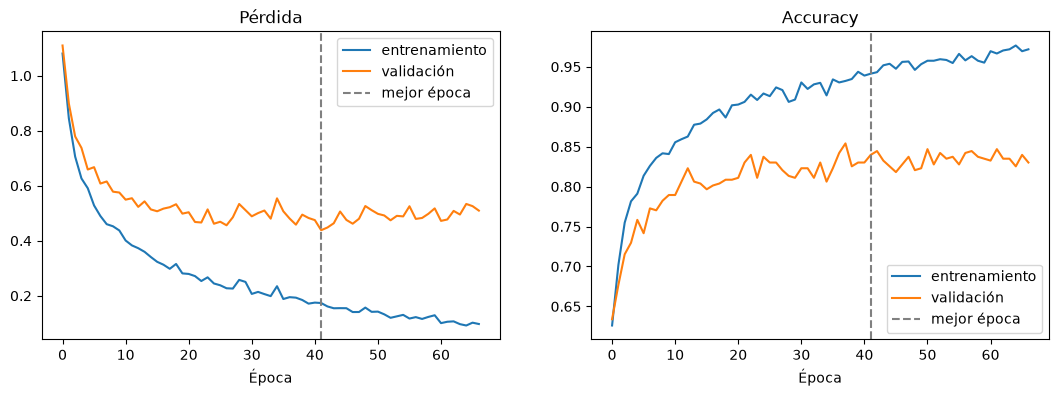

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.plot(historial["loss_train"], label="entrenamiento")
ax1.plot(historial["loss_val"], label="validación")
ax1.axvline(mejor_epoca - 1, color="gray", linestyle="--", label="mejor época")
ax1.set_title("Pérdida"); ax1.set_xlabel("Época"); ax1.legend()

ax2.plot(historial["acc_train"], label="entrenamiento")
ax2.plot(historial["acc_val"], label="validación")
ax2.axvline(mejor_epoca - 1, color="gray", linestyle="--", label="mejor época")
ax2.set_title("Accuracy"); ax2.set_xlabel("Época"); ax2.legend()
plt.show()

Accuracy en test: 0.758

              precision    recall  f1-score   support

     alegria      1.000     0.900     0.947        60
        asco      0.704     0.644     0.673        59
      enfado      0.710     0.817     0.760        60
       miedo      0.561     0.383     0.455        60
     neutral      0.869     0.914     0.891        58
    sorpresa      0.716     0.883     0.791        60
    tristeza      0.719     0.767     0.742        60

    accuracy                          0.758       417
   macro avg      0.754     0.758     0.751       417
weighted avg      0.754     0.758     0.751       417

Accuracy por ángulo:
  frente          0.793  (140 caras)
  semiperfil_der  0.786  (140 caras)
  semiperfil_izq  0.693  (137 caras)

Confianza media en aciertos:
  alegria    0.95
  asco       0.90
  enfado     0.82
  miedo      0.80
  neutral    0.93
  sorpresa   0.90
  tristeza   0.87


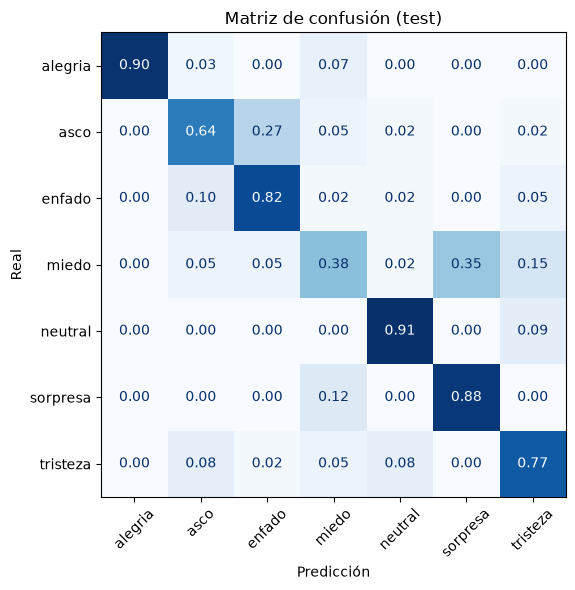

In [10]:
# ---------- Evaluación final con el test ----------
modelo.eval()
with torch.no_grad():
    salida = modelo(torch.from_numpy(X_test).to(dispositivo))
    prob_test = torch.softmax(salida, dim=1).cpu().numpy()
pred_test = prob_test.argmax(1)

print(f"Accuracy en test: {(pred_test == y_test).mean():.3f}\n")
print(classification_report(y_test, pred_test, target_names=EMOCIONES, digits=3))

# Accuracy según el ángulo de la foto
angulos_test = angulos[idx_test]
print("Accuracy por ángulo:")
for ang in np.unique(angulos_test):
    m = angulos_test == ang
    print(f"  {ang:15s} {(pred_test[m] == y_test[m]).mean():.3f}  ({m.sum()} caras)")

# Confianza media del modelo cuando acierta, por emoción (útil para los umbrales del juego)
print("\nConfianza media en aciertos:")
for i, emo in enumerate(EMOCIONES):
    m = (y_test == i) & (pred_test == i)
    print(f"  {emo:10s} {prob_test[m, i].mean():.2f}" if m.any() else f"  {emo:10s} -")

# Matriz de confusión normalizada (cada fila suma 1)
cm = confusion_matrix(y_test, pred_test, normalize="true")
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=EMOCIONES).plot(ax=ax, cmap="Blues", values_format=".2f",
                                                           colorbar=False)
ax.set_title("Matriz de confusión (test)")
ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(CARPETA_TIPO / "curvas.png", dpi=150, bbox_inches="tight")
plt.show()

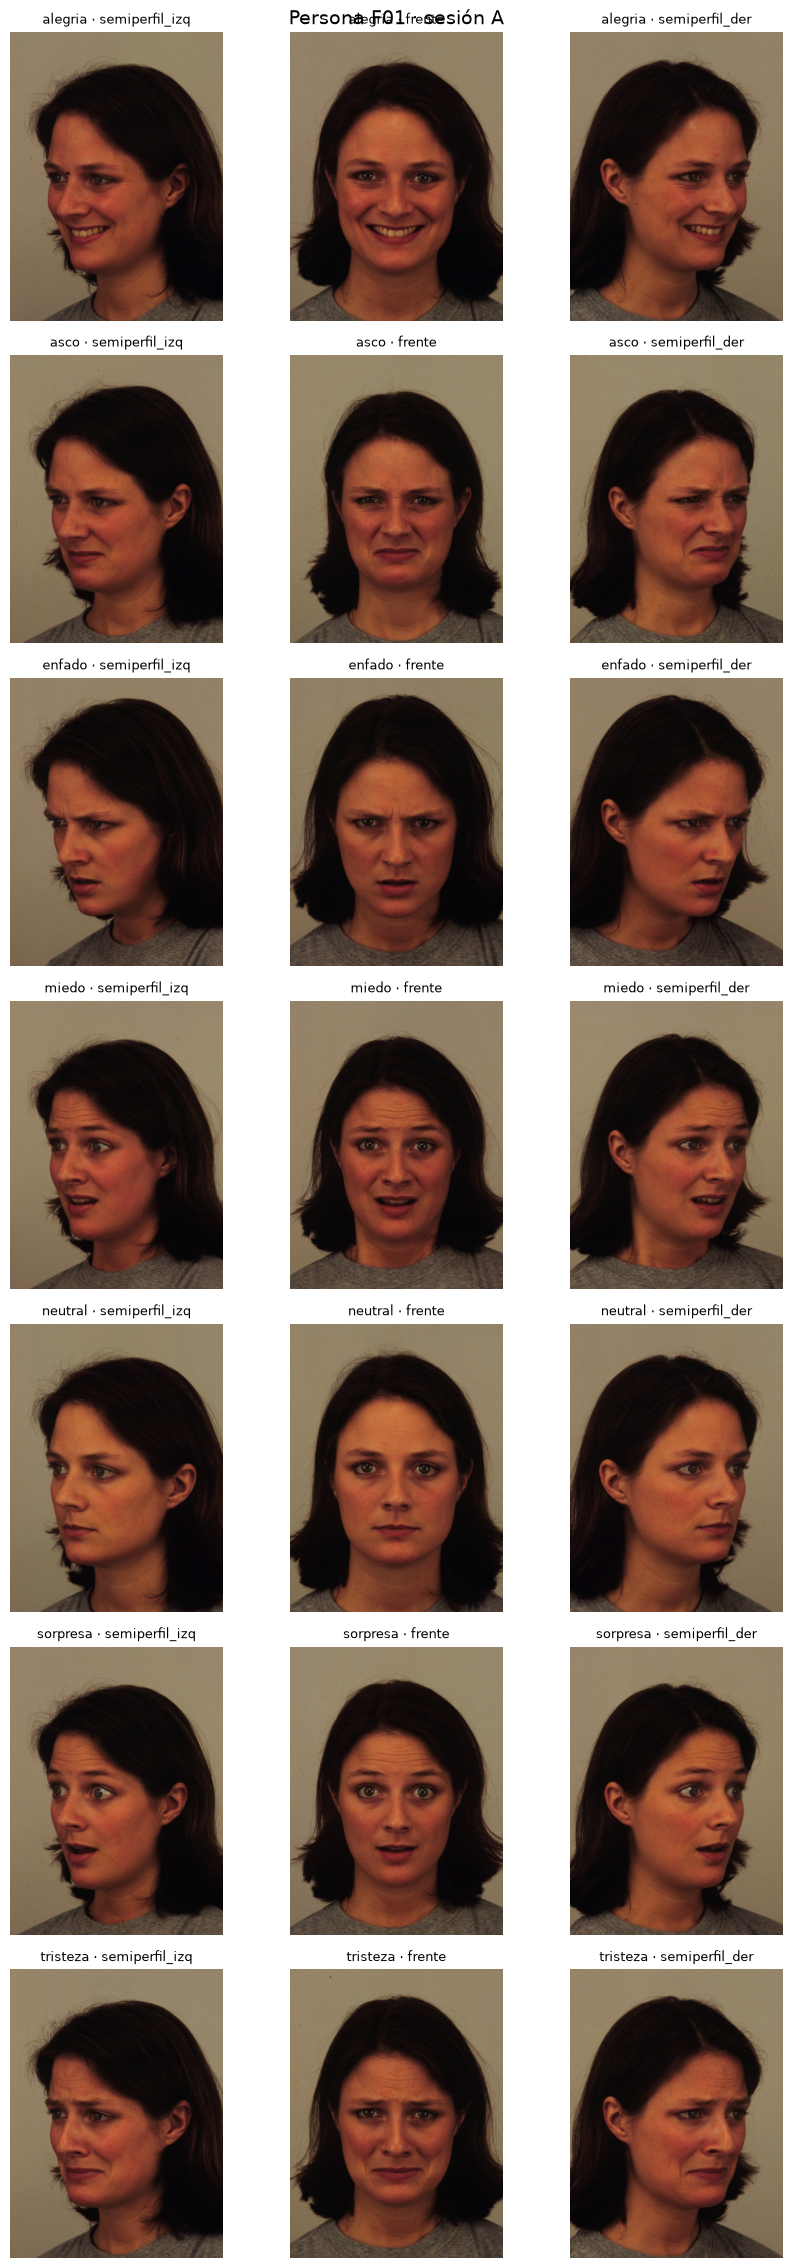

In [51]:
# TEMPORAL:
# ---------- Ver todas las fotos de una persona (ángulos usados) ----------
PERSONA = "F01"   # cambia por otra: F01..F35, M01..M35
SESION  = "A"     # A o B

ORDEN_ANGULOS = ["semiperfil_izq", "frente", "semiperfil_der"]
ORDEN_EMOCIONES = sorted(df_usar["emocion"].unique())

sub = df_usar[(df_usar["persona"] == PERSONA) & (df_usar["sesion"] == SESION)]
fig, ejes = plt.subplots(len(ORDEN_EMOCIONES), len(ORDEN_ANGULOS),
                         figsize=(3 * len(ORDEN_ANGULOS), 3.3 * len(ORDEN_EMOCIONES)))

for i, emo in enumerate(ORDEN_EMOCIONES):
    for j, ang in enumerate(ORDEN_ANGULOS):
        eje = ejes[i, j]
        eje.axis("off")
        fila = sub[(sub["emocion"] == emo) & (sub["angulo"] == ang)]
        if fila.empty:
            eje.text(0.5, 0.5, "no disponible", ha="center", va="center")
        else:
            img = leer_imagen(fila.iloc[0]["ruta"])
            eje.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        eje.set_title(f"{emo} · {ang}", fontsize=9)

fig.suptitle(f"Persona {PERSONA} · sesión {SESION}", fontsize=14)
plt.tight_layout()
plt.show()